Part 1 – Understand the Classification Problem (15 points)

1. Explore the dataset (7 points)

• Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.

• Identify one numerical and one categorical feature.

• Answer: Why must past_due_rent be excluded from the input features?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the CSV file into pandas
df = pd.read_csv('/content/SLCM_rent_arrears_student_clean.csv')

# Display data shape
rows, cols = df.shape
print(f"Dataset Dimensions: {rows} rows x {cols} columns\n")

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Print column names
print("\nColumn names:")
print(df.columns.tolist())

# Display missing-value counts
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print("\nMissing values per column:")
display(missing_summary)

# Summary statistics for numerical columns
num_summary_cols = ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent', 'past_due_rent']
stats_summary = df[num_summary_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T.round(2)
print("\nSummary Statistics for Numerical Columns:")
display(stats_summary)

Dataset Dimensions: 1754 rows x 14 columns

First 5 rows of the dataset:


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5



Column names:
['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']

Missing values per column:


,Missing Count,Missing Percentage (%)
record_id,0,0.00
adults_in_household,0,0.00
children_in_household,0,0.00
household_has_65plus,0,0.00
monthly_household_income,108,6.16
income_sources,0,0.00
employment_status,0,0.00
has_housing_voucher,0,0.00
eviction_in_progress,1,0.06
behind_on_utilities,7,0.40



Summary Statistics for Numerical Columns:


,count,mean,median,std,min,max
adults_in_household,1754.0,1.39,1.0,0.92,0.0,6.0
children_in_household,1754.0,1.07,1.0,1.27,0.0,6.0
monthly_household_income,1646.0,1303.93,1000.0,1285.93,0.0,10000.0
monthly_rent,1746.0,967.05,975.0,451.09,0.0,4300.0
past_due_rent,1754.0,2408.01,2000.0,2089.52,0.0,20000.0


**Dataset Overview & Missing Values:** The dataset contains 1,754 household intake records across 14 columns. Five columns contain missing values: `monthly_household_income` (108 missing, 6.16%), `main_reason_behind_on_rent` (16 missing, 0.91%), `monthly_rent` (8 missing, 0.46%), `behind_on_utilities` (7 missing, 0.40%), and `eviction_in_progress` (1 missing, 0.06%).

**Feature Identification:**
* **One Numerical Feature:** `monthly_rent` (`float64` — continuous monthly rent amount in dollars).
* **One Categorical Feature:** `employment_status` (`object` — nominal text categories describing the applicant's employment situation).

**Why `past_due_rent` Must Be Excluded:** The target variable `high_arrears` is directly calculated from `past_due_rent` (`1` if `past_due_rent >= $3,000`, otherwise `0`). Including `past_due_rent` in the input features `X` would cause **target leakage (data leakage)**, allowing the classifiers to trivially determine the label from the exact dollar amount rather than learning predictive patterns from household and housing characteristics.

2. Create the target (8 points)

• Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.

• Show class counts and one bar chart of high_arrears.

• Answer: Which class is larger? Why might accuracy alone be misleading?

Class counts for high_arrears:


,Class Count,Percentage (%)
"0 (< $3,000)",1210,68.99
"1 ($3,000+)",544,31.01


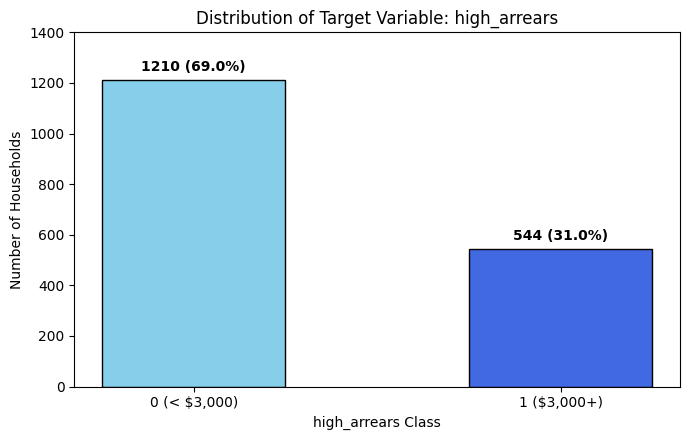

In [2]:
# 2. Create high_arrears target variable (1 if past_due_rent >= 3000, else 0)
df['high_arrears'] = (df['past_due_rent'] >= 3000).astype(int)

# Show class counts and percentages
class_counts = df['high_arrears'].value_counts().sort_index()
class_pcts = (df['high_arrears'].value_counts(normalize=True).sort_index() * 100).round(2)

class_summary = pd.DataFrame({
    'Class Count': class_counts,
    'Percentage (%)': class_pcts
})
class_summary.index = ['0 (< $3,000)', '1 ($3,000+)']
print("Class counts for high_arrears:")
display(class_summary)

# Create bar chart of high_arrears
plt.figure(figsize=(7, 4.5))
bars = plt.bar(['0 (< $3,000)', '1 ($3,000+)'], class_counts.values,
               color=['skyblue', 'royalblue'], edgecolor='black', width=0.5)
plt.title("Distribution of Target Variable: high_arrears")
plt.xlabel("high_arrears Class")
plt.ylabel("Number of Households")
plt.ylim(0, 1400)

for bar in bars:
    height = int(bar.get_height())
    pct = height / len(df) * 100
    plt.text(bar.get_x() + bar.get_width() / 2., height + 25,
             f"{height} ({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Which Class Is Larger:** Class '0' (households owing less than 3,000 in past-due rent) is the larger class with **1,210 households (68.99%)**, compared to **544 households (31.01%)** in Class `1` (3,000 or more in past-due rent).

**Why Accuracy Alone Might Be Misleading:** Because the dataset is imbalanced (~69% Class 0 vs. ~31% Class 1), a trivial model that predicts `0` for every single household would achieve **68.99% accuracy** while catching **0%** of the high-arrears households (Recall = 0). Evaluating models with **Recall** and **F1** for Class 1 is necessary to measure how well they actually identify households experiencing severe rent arrears.

Part 2 – Prepare the Data (25 points)

3. Select features and split (10 points)

• Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.

• Split the data once into training and testing sets.

• Answer: Why do we keep a separate test set?

In [3]:
from sklearn.model_selection import train_test_split

# 3. Create X and y
X = df.drop(columns=['record_id', 'past_due_rent', 'high_arrears'])
y = df['high_arrears']

# Split the data once into 80/20 training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train dimensions: {X_train.shape}")
print(f"X_test dimensions:  {X_test.shape}")
print(f"y_train dimensions: {y_train.shape} (Class 1 proportion: {y_train.mean():.4f})")
print(f"y_test dimensions:  {y_test.shape} (Class 1 proportion: {y_test.mean():.4f})")

X_train dimensions: (1403, 12)
X_test dimensions:  (351, 12)
y_train dimensions: (1403,) (Class 1 proportion: 0.3100)
y_test dimensions:  (351,) (Class 1 proportion: 0.3105)


**Train/Test Split Summary:** The data is split into 1,403 training records and 351 testing records across 12 input features, with `stratify=y` ensuring that both sets maintain the exact same ~31.0% proportion of high-arrears households.

**Why We Keep a Separate Test Set:** We hold out a separate test set so we can evaluate our trained models on unseen data, which provides an honest estimate of how well the models will generalize to new community households. Evaluating on the same data used for training or tuning can mask overfitting, where a model memorizes training noise rather than learning generalizable patterns.

4. Build one reusable preprocessor (15 points)

• Identify numerical and categorical columns with select_dtypes.

• Numerical: fill missing values using median and apply StandardScaler.

• Categorical: fill missing values using most_frequent and apply OneHotEncoder(handle_unknown="ignore").

• Combine with ColumnTransformer. You may reuse the class example.

• Answer: Why is scaling helpful for KNN and SVC?

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 4. Identify numerical and categorical columns with select_dtypes
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine with ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_features),
    ('cat', cat_pipeline, categorical_features)
])

print("\nCombined Preprocessor:")
print(preprocessor)

Numerical features: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical features: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']

Combined Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['adults_in_household',
                                  'children_in_household',
                                  'monthly_household_income', 'monthly_rent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
   

**Reusable Preprocessor Summary:** The `ColumnTransformer` bundles median imputation and `StandardScaler` for the 4 numerical features alongside mode (`most_frequent`) imputation and `OneHotEncoder(handle_unknown="ignore")` for the 8 categorical features, ensuring all preprocessing statistics are learned solely from the training set inside each pipeline.

**Why Scaling Is Helpful for KNN and SVC:** KNN classifies observations by calculating geometric distances between points, and SVC finds a maximum-margin boundary sensitive to feature scales and regularization penalties. Without `StandardScaler`, large-scale dollar variables (`monthly_household_income` up to 10,000 and `monthly_rent` up to 4,300) would dominate the distance and margin calculations over small-scale count variables (`adults_in_household` and `children_in_household` ranging from 0 to 6).

Part 3 – Train and Compare Five Models (45 points)

5. Train the five classifiers (20 points)

• Build five pipelines with the same preprocessor, the same training set, and these models:
  • Logistic Regression: LogisticRegression(max_iter=1000)
  • KNN: KNeighborsClassifier(n_neighbors=5)
  • Decision Tree: DecisionTreeClassifier(max_depth=5, random_state=42)
  • Random Forest: RandomForestClassifier(n_estimators=100, random_state=42)
  • Support Vector Classifier: SVC()

• Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not need a loop or custom functions.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score

# 1. Logistic Regression
lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])
lr_pipe.fit(X_train, y_train)
lr_pred = lr_pipe.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)
lr_rec = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
print(f"Logistic Regression -> Accuracy: {lr_acc:.4f}, Recall: {lr_rec:.4f}, F1: {lr_f1:.4f}")

# 2. KNN
knn_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])
knn_pipe.fit(X_train, y_train)
knn_pred = knn_pipe.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)
knn_rec = recall_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)
print(f"KNN (n_neighbors=5) -> Accuracy: {knn_acc:.4f}, Recall: {knn_rec:.4f}, F1: {knn_f1:.4f}")

# 3. Decision Tree
dt_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=5, random_state=42))
])
dt_pipe.fit(X_train, y_train)
dt_pred = dt_pipe.predict(X_test)
dt_acc = accuracy_score(y_test, dt_pred)
dt_rec = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
print(f"Decision Tree       -> Accuracy: {dt_acc:.4f}, Recall: {dt_rec:.4f}, F1: {dt_f1:.4f}")

# 4. Random Forest
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42))
])
rf_pipe.fit(X_train, y_train)
rf_pred = rf_pipe.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
print(f"Random Forest       -> Accuracy: {rf_acc:.4f}, Recall: {rf_rec:.4f}, F1: {rf_f1:.4f}")

# 5. Support Vector Classifier (SVC)
svc_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC())
])
svc_pipe.fit(X_train, y_train)
svc_pred = svc_pipe.predict(X_test)
svc_acc = accuracy_score(y_test, svc_pred)
svc_rec = recall_score(y_test, svc_pred)
svc_f1 = f1_score(y_test, svc_pred)
print(f"SVC                 -> Accuracy: {svc_acc:.4f}, Recall: {svc_rec:.4f}, F1: {svc_f1:.4f}")

Logistic Regression -> Accuracy: 0.6952, Recall: 0.3028, F1: 0.3815
KNN (n_neighbors=5) -> Accuracy: 0.6809, Recall: 0.3761, F1: 0.4227
Decision Tree       -> Accuracy: 0.6952, Recall: 0.3303, F1: 0.4022
Random Forest       -> Accuracy: 0.7037, Recall: 0.3211, F1: 0.4023
SVC                 -> Accuracy: 0.7066, Recall: 0.2294, F1: 0.3268


**Model Training Interpretation:** All five pipelines were fitted on the same 1,403 training rows and evaluated on the 351 held-out test rows. Although test accuracy is similar across all five classifiers (ranging from 0.6809 to 0.7066), their ability to detect Class 1 (`high_arrears`) differs noticeably: KNN achieves the highest test F1 (0.4227) and Recall (0.3761), followed by Random Forest (F1 = 0.4023) and Decision Tree (F1 = 0.4022), while SVC has the lowest Recall (0.2294) and F1 (0.3268).

6. Compare the models (10 points)

• Put the test results in one table with columns: Model, Accuracy, Recall, F1.

• Create one confusion matrix for the model with the highest test F1.

• Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

Test Set Comparison Table:


,Model,Accuracy,Recall,F1
0,Logistic Regression,0.6952,0.3028,0.3815
1,KNN,0.6809,0.3761,0.4227
2,Decision Tree,0.6952,0.3303,0.4022
3,Random Forest,0.7037,0.3211,0.4023
4,SVC,0.7066,0.2294,0.3268


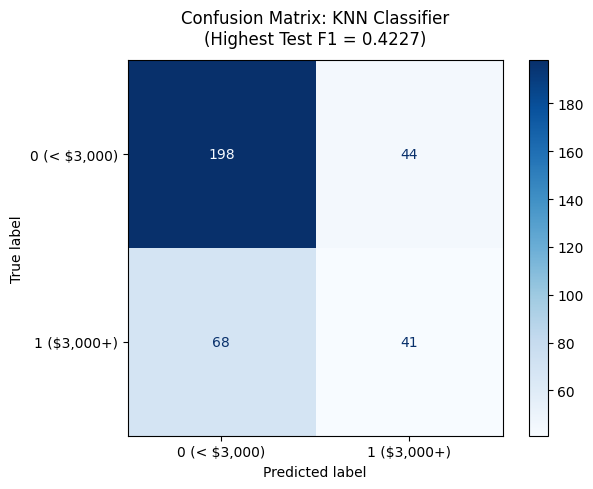

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 6. Put test results in one comparison table
comparison_table = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVC'],
    'Accuracy': [lr_acc, knn_acc, dt_acc, rf_acc, svc_acc],
    'Recall': [lr_rec, knn_rec, dt_rec, rf_rec, svc_rec],
    'F1': [lr_f1, knn_f1, dt_f1, rf_f1, svc_f1]
}).round(4)

print("Test Set Comparison Table:")
display(comparison_table)

# Create confusion matrix for the model with the highest test F1 (KNN: F1 = 0.4227)
cm_knn = confusion_matrix(y_test, knn_pred)
fig, ax = plt.subplots(figsize=(6.5, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=['0 (< $3,000)', '1 ($3,000+)']
)
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title('Confusion Matrix: KNN Classifier\n(Highest Test F1 = 0.4227)', pad=12)
plt.tight_layout()
plt.show()

**Confusion Matrix Interpretation:** On the 351 test households, the **KNN** classifier (highest test F1 = 0.4227) correctly predicts **198 true negatives** (below 3,000) and **41 true positives** (3,000+ arrears), while making **44 false positive** errors (false alarms) and **68 false negative** errors (missed high-arrears cases).

**Which Model Catches the Highest Proportion of High-Arrears Households:** **KNN** catches the highest proportion of high-arrears households, with a test **Recall of 0.3761 (37.61%, or 41 out of 109 actual high-arrears test households)**, followed by Decision Tree (33.03%) and Random Forest (32.11%).

**What a Missed Case Means for SLCM:** A missed case (False Negative) occurs when a household actually owes 3,000 or more in overdue rent (`high_arrears = 1`), but the model predicts `0`. For SLCM, a missed case means a family in severe housing distress and at heightened risk of eviction may not be flagged early for intensive casework, legal aid referral, or larger emergency rental assistance coordination.

7. Try a small GridSearchCV (15 points)

• Tune only two models on the training set with cv=3 and scoring="f1".

• For KNN, try n_neighbors = [3, 5, 7].

• For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100).

• Print best_params_ and best_score_ for each search. No extra charts or second search are needed.

• Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

In [7]:
from sklearn.model_selection import GridSearchCV

# 7. GridSearchCV for KNN
knn_grid = {'model__n_neighbors': [3, 5, 7]}
knn_search = GridSearchCV(knn_pipe, knn_grid, cv=3, scoring='f1')
knn_search.fit(X_train, y_train)

print("Best KNN parameters:", knn_search.best_params_)
print("Best KNN CV F1 score:", round(knn_search.best_score_, 4))

# GridSearchCV for Random Forest
rf_grid = {'model__max_depth': [3, 5, None]}
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=3, scoring='f1')
rf_search.fit(X_train, y_train)

print("\nBest Random Forest parameters:", rf_search.best_params_)
print("Best Random Forest CV F1 score:", round(rf_search.best_score_, 4))

Best KNN parameters: {'model__n_neighbors': 7}
Best KNN CV F1 score: 0.4855

Best Random Forest parameters: {'model__max_depth': None}
Best Random Forest CV F1 score: 0.4575


**Which Model Has the Higher Best Cross-Validation F1:** **KNN** has the higher best 3-fold cross-validation F1 score at **0.4855** (with `n_neighbors = 7`), compared to **Random Forest**, which achieved a best cross-validation F1 score of **0.4575** (with `max_depth = None`).

**Why `GridSearchCV` Is Fitted on Training Data Only:** `GridSearchCV` must be fitted on the training data only so that hyperparameter choices do not leak information from the test set into the model selection process. If we tuned hyperparameters using the test set, our final test metrics would be overly optimistic and would no longer measure true generalization on unseen households.

Part 4 – Explain the Results (15 points)

8. Interpret your comparison (8 points)

• In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not accuracy alone.

• Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

Based on our evaluation results, **KNN** (alongside the tree-based **Random Forest** and **Decision Tree** models) is the most promising model for identifying households with $3,000 or more in past-due rent. Although Support Vector Classifier (SVC) achieved the highest test accuracy (70.66%), it had the worst recall (22.94%) and lowest F1 score (0.3268) because it mostly predicted the majority class (`0`), whereas **KNN** achieved the highest test F1 score (**0.4227**), highest test recall (**37.61%**), and highest cross-validation F1 score (**0.4855**). A more complex model did not necessarily perform better: the 100-tree Random Forest ensemble (F1 = 0.4023, Recall = 32.11%) performed almost identically to a single depth-5 Decision Tree (F1 = 0.4022, Recall = 33.03%) and trailed the simpler KNN classifier in both recall and F1. SLCM should pay particularly close attention to **false negatives (missed cases)**, which were frequent across all models (even KNN missed 68 out of 109 high-arrears test households) and represent deeply distressed families who could be overlooked if staff relied solely on automated flags. At the same time, SLCM must also watch **false positives (false alarms)** (44 cases in KNN) so that staff time and emergency funds are verified against actual lease documentation rather than assigned by model predictions alone.

9. Recommendation to SLCM (7 points)

• Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model performed, one practical insight, and one limitation.

• State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

In this analysis, we used household and housing intake information—including monthly rent, household income, family size, employment status, utility shutoff risk, and eviction status—to predict whether a household owes **3,000 or more in past-due rent** (`high_arrears`). Our best-performing classification model (**KNN**) achieved a test F1 score of **0.4227** and correctly identified **37.6% (41 out of 109)** of the high-arrears households in our test group, showing that intake survey data provides a useful early warning signal but still misses many severe cases. One practical insight is that households with higher monthly contract rent (averaging ~1,170/month among high-arrears households vs. ~876/month among lower-arrears households) and active eviction proceedings are substantially more likely to owe 3,000 or more, which can help SLCM anticipate when an incoming client may require multi-month rental relief or legal aid referrals. However, an important limitation is that intake forms do not record how many months a tenant has been behind or how lenient their landlord has been, which limits how accurately any model can separate high-arrears households from moderate-arrears households. **Finally, a model prediction reflects statistical patterns in historical data—not proof of cause and effect—and must never be used alone to decide a household's eligibility for financial assistance.**